# Slot 5: Borrow a pretrained DNA model

**Technion AI Days 2026: Teaching Machines to Read DNA**

In Slot 2 you trained a CNN from scratch on our data only. Now we borrow a **foundation model**: a
language model trained on the human genome to predict each token (a short stretch of DNA) from the
tokens before it. This general-purpose training is called *pretraining*. The model has never seen
an AGO2 label.

The method (from Roee's Slot 4):

1. turn each sequence into one vector, its **embedding**: the model's last-layer output, averaged
   over the real (non-padding) tokens;
2. train a **linear probe** to predict bound vs unbound: a logistic regression on the embeddings.
   The language model's weights are not updated; we say the model is *frozen*.

Use an AI assistant (Gemini in Colab, or any chat assistant) as much as you like. Each TODO states
what to build, the variable names to use, the gotchas to tell your assistant, and a check with the
number to expect. Run the check before you move on.

| cell | what you do |
|---|---|
| `#@title ... run this cell, nothing to change` | run it |
| `# TODO-N` with `# === Your code here ===` | write it (yourself or with an assistant), then check it |
| `#@title Stuck? ...` | run it only if your TODO doesn't pass its check: it defines our version |

In [1]:
#@title Setup - run this cell, nothing to change { display-mode: "form" }
import os, time, urllib.request
from pathlib import Path
import numpy as np
import torch
from torch import nn, optim
from sklearn.metrics import roc_auc_score

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU - Runtime > Change runtime type > T4 GPU")

# Plot style, shared by every notebook (the same palette as the slides).
import logging
import matplotlib.pyplot as plt
from matplotlib import cycler
from matplotlib.colors import LinearSegmentedColormap

INK, MUTED, MIDGREY, LIGHTGREY, HAIRLINE = "#202124", "#5F6368", "#80868B", "#C4C7C5", "#DADCE0"
ACCENT = "#1A73E8"
BOUND, UNBOUND = ACCENT, LIGHTGREY                            # class colours
CNN_C, FROZEN_C, FINETUNED_C, BASELINE_C = INK, MIDGREY, ACCENT, MIDGREY   # model colours
BASE_COLOURS = {"A": "#0F9D58", "C": "#4285F4", "G": "#F4B400", "U": "#DB4437", "T": "#DB4437"}  # logos only
CMAP_DIV = LinearSegmentedColormap.from_list("ws_div", [MUTED, "#FFFFFF", ACCENT])         # weight heatmaps
CMAP_SEQ = LinearSegmentedColormap.from_list("ws_seq", ["#E8F0FE", ACCENT, "#174EA6"])     # sequential values

plt.colormaps.register(CMAP_SEQ, force=True)
plt.colormaps.register(CMAP_DIV, force=True)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # Colab has no Roboto: fall back quietly
plt.rcParams.update({
    "font.family": ["Roboto", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.prop_cycle": cycler(color=[ACCENT, INK, MIDGREY, LIGHTGREY]),
    "axes.grid": False, "grid.color": HAIRLINE, "grid.linewidth": 0.8,
    "legend.frameon": False, "legend.fontsize": 8,
    "image.cmap": "ws_seq",
})

# Where the workshop files live. Either one direct-download link per file (FILE_URLS, e.g. SharePoint
# "anyone with the link" + download=1), or one folder URL (DATA_URL, e.g. a Hugging Face dataset repo).
FILE_URLS = {}
DATA_URL = os.environ.get("AIDAYS_DATA_URL", "https://huggingface.co/datasets/yup8/ai-days-2026-ago2/resolve/main")
DATA_DIR = Path(os.environ.get("AIDAYS_DATA_DIR", "data"))
DATA_DIR.mkdir(exist_ok=True)

try:
    from google.colab import files as _colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def fetch(name):
    """Return the local path of a workshop file, downloading it first if needed."""
    path = DATA_DIR / name
    if not path.exists():
        url = FILE_URLS.get(name) or (f"{DATA_URL.rstrip('/')}/{name}" if DATA_URL else "")
        if not url:
            raise FileNotFoundError(f"{path} not found and no download link is set for it")
        t = time.time()
        urllib.request.urlretrieve(url, path)
        print(f"downloaded {name} ({path.stat().st_size / 1e6:.1f} MB) in {time.time() - t:.1f}s")
    return path


def download_outputs(*names):
    """End of a notebook: save your results to your laptop so the next notebook can use them."""
    for n in names:
        p = DATA_DIR / n
        if not p.exists():
            print(f"{n}: not found (did the cell that makes it run?)")
        elif IN_COLAB:
            _colab_files.download(str(p))
        else:
            print(f"{n}: saved at {p}")


def upload_yours():
    """Start of a notebook: upload the files you downloaded at the end of an earlier notebook."""
    if not IN_COLAB:
        print(f"not in Colab: copy your files into {DATA_DIR}")
        return
    import re
    for n, b in _colab_files.upload().items():
        clean = re.sub(r" \(\d+\)(?=\.[^.]+$)", "", n)   # "my_cnn (1).pt" -> "my_cnn.pt" (browser renames)
        (DATA_DIR / clean).write_bytes(b)
        print("uploaded", n, "->", clean)

device: cuda | NVIDIA A30


In [2]:
#@title Data helpers - run this cell, nothing to change { display-mode: "form" }
MAX_LEN  = 501          # fixed global length (pad / truncate)
ALPHABET = "ACGU"       # order = the 4 rows of the one-hot matrix
FILES = {split: (f"CLIPSEQ_AGO2.{split}.positives.fa", f"CLIPSEQ_AGO2.{split}.negatives.fa")
         for split in ("train", "ls")}


def read_fasta(path, label):
    """Return (sequences, labels) from a FASTA file, all with the same label.

    The files mix the DNA letter T and the RNA letter U for the same base,
    so we normalise everything to U.
    """
    seqs, labs = [], []
    with Path(path).open() as fh:
        for line in fh:
            if line.startswith(">"):
                continue
            seqs.append(line.strip().upper().replace("T", "U"))
            labs.append(label)
    return seqs, labs


def read_split(split):
    """'train' or 'ls' (the held-out validation set) -> (sequences, labels as a numpy array)."""
    pos, neg = FILES[split]
    p, lp = read_fasta(fetch(pos), 1)
    n, ln = read_fasta(fetch(neg), 0)
    return p + n, np.array(lp + ln)


_LUT = np.full(256, -1, dtype=np.int64)
for _i, _b in enumerate(ALPHABET):
    _LUT[ord(_b)] = _i


def encode_batch(seqs, max_len=MAX_LEN):
    """List of RNA strings -> one-hot FloatTensor (B, 1, 4, max_len).

    Pads/truncates to max_len; padding and unknown bases stay uniform 0.25.
    """
    X = np.full((len(seqs), 1, 4, max_len), 0.25, dtype=np.float32)
    for b, s in enumerate(seqs):
        idx = _LUT[np.frombuffer(s[:max_len].encode(), dtype=np.uint8)]
        pos = np.nonzero(idx >= 0)[0]
        X[b, 0, :, pos] = 0.0
        X[b, 0, idx[pos], pos] = 1.0
    return torch.from_numpy(X)

In [3]:
#@title Foundation-model helpers - run this cell, nothing to change { display-mode: "form" }
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import transformers
transformers.logging.set_verbosity_error()

FM_REPO = "RaphaelMourad/Mistral-DNA-v1-17M-hg38"            # 16M parameters, pretrained on the human genome
NT_REPO = "InstaDeepAI/nucleotide-transformer-500m-human-ref"  # 486M parameters


def to_dna(seq):
    """The DNA language models expect T, not U."""
    return seq.replace("U", "T")


def workshop_data(n_train=12000, seed=0):
    """Train: a fixed random 12k subset of the training file (the same in Slots 5-6).
    Test: the held-out 'ls' set - the same test set the Slot 2 CNN was measured on."""
    seqs, y = read_split("train")
    tr = np.random.default_rng(seed).permutation(len(seqs))[:n_train]
    test_seqs, test_y = read_split("ls")
    return [seqs[i] for i in tr], y[tr], test_seqs, test_y


def load_fm(repo=FM_REPO):
    """Download (first time only) and load a DNA language model + its tokenizer."""
    from transformers import AutoModel, AutoTokenizer
    tok = AutoTokenizer.from_pretrained(repo, trust_remote_code=True)
    model = AutoModel.from_pretrained(repo, trust_remote_code=True).to(DEVICE).eval()
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token or tok.unk_token
    return tok, model

In [4]:
#@title The data: a fixed subset of AGO2 sequences - run this cell { display-mode: "form" }
S_train, y_train, S_test, y_test = workshop_data()
S_train, S_test = [to_dna(s) for s in S_train], [to_dna(s) for s in S_test]
print(f"train {len(S_train):,} | test {len(S_test):,} | bound: {y_train.mean():.0%}")
print("example:", S_train[0][:70], "...")

train 12,000 | test 1,000 | bound: 51%
example: TGATTTATCAAGAGTATTTTCATTTTTCAATCCATAAATGTGGAAATGAACTATGATCAGCAGAGTTGGG ...


## 1. Load a pretrained DNA language model

**Mistral-DNA** (Mourad, 2024): 16 million parameters (the "17M" in its name counts the output layer
we don't use), pretrained on the human genome (hg38). Its tokenizer splits DNA into tokens:
substrings of varying length, from a vocabulary of 4,096 that was built from the genome. `[CLS]` and `[SEP]` are special tokens the tokenizer adds at the
start and end; they are not DNA.

In [5]:
#@title Download + load the model, look at its tokens - run this cell { display-mode: "form" }
t0 = time.time()
tok, fm = load_fm(FM_REPO)
print(f"loaded {FM_REPO} in {time.time() - t0:.1f}s | "
      f"{sum(p.numel() for p in fm.parameters()) / 1e6:.0f}M parameters | hidden size {fm.config.hidden_size}")
ids = tok(S_train[0][:60])["input_ids"]
print("\nfirst 60 letters :", S_train[0][:60])
print("as tokens        :", " | ".join(tok.convert_ids_to_tokens(ids)))

Loading weights:   0%|          | 0/74 [00:00<?, ?it/s]

loaded RaphaelMourad/Mistral-DNA-v1-17M-hg38 in 2.8s | 16M parameters | hidden size 256

first 60 letters : TGATTTATCAAGAGTATTTTCATTTTTCAATCCATAAATGTGGAAATGAACTATGATCAG
as tokens        : [CLS] | TGATTTA | TCAA | GAGTA | TTTT | CATTTT | TCAA | TCCA | TAAATGTG | GAAATGAA | CTA | TGATCA | G | [SEP]


### TODO-1: Turn sequences into vectors

**Build** `embed(tok, model, seqs, batch=128)`: a list of DNA strings in, a numpy array of shape
`(len(seqs), 256)` out, one vector per sequence. For each batch of sequences:

1. tokenize with `padding=True, truncation=True, max_length=512, return_tensors="pt"`;
2. run the model with `output_hidden_states=True` under `torch.no_grad()`;
3. take the **last** layer, `outputs.hidden_states[-1]`: shape (batch, tokens, 256);
4. average over the **real** tokens only.

**Gotchas to tell your assistant:**
- sequences in a batch have different lengths, so the tokenizer **pads** the short ones; the
  `attention_mask` is 1 for real tokens and 0 for padding. Average with the mask, not with `.mean(1)`.
- move `input_ids` and `attention_mask` to `DEVICE`, and the result back with `.cpu().numpy()`.
- the tokenizer returns more keys than the model accepts; pass only `input_ids` and `attention_mask`.

**Check** (the next cell runs it): shape `(3, 256)`, and the same sequence must give the **same**
vector whether it is embedded alone or next to a longer one (padding must not change it).

In [6]:
# TODO-1: the embed function
# === Your code here ===
...
# === End of your code ===

E = embed(tok, fm, S_train[:3])
short = min(S_train[:50], key=len); long_ = max(S_train[:50], key=len)
alone, padded = embed(tok, fm, [short]), embed(tok, fm, [short, long_])[:1]
print("check 1, shape:", E.shape, "(want (3, 256))")
print("check 2, padding ignored:", np.allclose(alone, padded, atol=2e-2), "(want True)")

NameError: name 'embed' is not defined

In [7]:
#@title Stuck? Run this only if TODO-1 failed its checks: it defines our embed() { display-mode: "form" }
#@title Embedding + probe helpers (written in Slot 5) - run this cell, nothing to change { display-mode: "form" }
@torch.no_grad()
def embed(tok, model, seqs, batch=128):
    """List of DNA strings -> (N, hidden) numpy array: the mean of the last layer over real tokens."""
    model.eval()
    out = []
    for i in range(0, len(seqs), batch):
        enc = tok(seqs[i:i + batch], return_tensors="pt", padding=True, truncation=True, max_length=512)
        ids, mask = enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            h = model(input_ids=ids, attention_mask=mask, output_hidden_states=True).hidden_states[-1].float()
        m = mask.unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.concatenate(out)


def probe_auc(E_train, y_train, E_test, y_test, C=0.1):
    """Fit a linear probe (logistic regression) on the training vectors; AUROC on the test vectors."""
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=C))
    probe.fit(E_train, y_train)
    return roc_auc_score(y_test, probe.predict_proba(E_test)[:, 1]), probe
print("using the reference embed() and probe_auc()")

using the reference embed() and probe_auc()


In [8]:
#@title Embed all sequences - run this cell, nothing to change { display-mode: "form" }
t0 = time.time()
E_train, E_test = embed(tok, fm, S_train), embed(tok, fm, S_test)
print(f"embedded {len(S_train) + len(S_test):,} sequences in {time.time() - t0:.1f}s -> {E_train.shape[1]} numbers each")
np.savez_compressed(DATA_DIR / "my_emb_mistral17m.npz", train=E_train, test=E_test)

embedded 13,000 sequences in 7.4s -> 256 numbers each


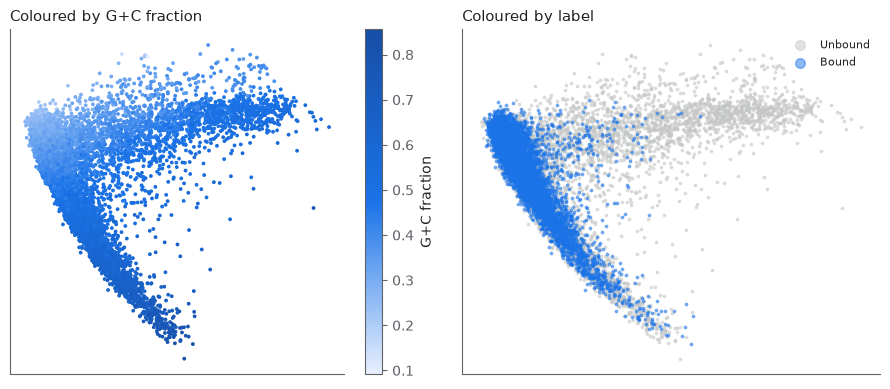

correlation of direction 1 with G+C: +0.52


In [9]:
#@title A 2-D map of the vectors - run this cell { display-mode: "form" }
# PCA finds the 2 directions along which the 12,000 vectors vary most, so we can look at them.
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
P = PCA(2).fit_transform(StandardScaler().fit_transform(E_train))
gc_frac = np.array([(s.count("G") + s.count("C")) / len(s) for s in S_train])
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
sc = ax[0].scatter(*P.T, c=gc_frac, s=3, cmap=CMAP_SEQ); plt.colorbar(sc, ax=ax[0], label="G+C fraction")
for lab, col, name in ((0, UNBOUND, "Unbound"), (1, BOUND, "Bound")):
    ax[1].scatter(*P[y_train == lab].T, color=col, s=3, alpha=.5, label=name)
ax[1].legend(markerscale=4)
ax[0].set_title("Coloured by G+C fraction"); ax[1].set_title("Coloured by label")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print(f"correlation of direction 1 with G+C: {np.corrcoef(P[:, 0], gc_frac)[0, 1]:+.2f}")

**Reading the map.** If one colouring changes smoothly along the long axis of the cloud, that
property accounts for much of the variation between the vectors. Note which one it is; Slot 6
tests it.

### TODO-2: A linear probe

**Build** `probe_auc(E_train, y_train, E_test, y_test)`. It must **return a tuple `(auc, probe)`**:
the AUROC on the **test** set, and the fitted model. Inside:

1. standardise the features (`StandardScaler`: each of the 256 numbers is shifted and scaled to
   mean 0 and standard deviation 1 on the training set);
2. fit `LogisticRegression(max_iter=3000, C=0.1)` on the **training** vectors;
3. `probe.predict_proba(E_test)[:, 1]` = probability of "bound" → `roc_auc_score(y_test, ...)`.

**Gotchas to tell your assistant:** fit on train, score on test (never score the sequences you fit
on); use `make_pipeline(StandardScaler(), LogisticRegression(...))` so the scaling learned on train
is reused on test; return both values.

**Check:** the test AUROC should be **≈ 0.78**. If you get above 0.95, you probably scored the
training set.

In [10]:
# TODO-2: the linear probe
# === Your code here ===
...
# === End of your code ===

auc_fm, _ = probe_auc(E_train, y_train, E_test, y_test)
results = {"Mistral-DNA (16M), pretrained": auc_fm}
print(f"Mistral-DNA + linear probe: test AUROC = {auc_fm:.3f}   (want ≈ 0.78; the Slot 2 CNN: ~0.86)")

Mistral-DNA + linear probe: test AUROC = 0.782   (want ≈ 0.78; the Slot 2 CNN: ~0.86)


In [11]:
#@title Stuck? Run this only if TODO-2 failed its check: it defines our probe_auc() { display-mode: "form" }
#@title Embedding + probe helpers (written in Slot 5) - run this cell, nothing to change { display-mode: "form" }
@torch.no_grad()
def embed(tok, model, seqs, batch=128):
    """List of DNA strings -> (N, hidden) numpy array: the mean of the last layer over real tokens."""
    model.eval()
    out = []
    for i in range(0, len(seqs), batch):
        enc = tok(seqs[i:i + batch], return_tensors="pt", padding=True, truncation=True, max_length=512)
        ids, mask = enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            h = model(input_ids=ids, attention_mask=mask, output_hidden_states=True).hidden_states[-1].float()
        m = mask.unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.concatenate(out)


def probe_auc(E_train, y_train, E_test, y_test, C=0.1):
    """Fit a linear probe (logistic regression) on the training vectors; AUROC on the test vectors."""
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=C))
    probe.fit(E_train, y_train)
    return roc_auc_score(y_test, probe.predict_proba(E_test)[:, 1]), probe
auc_fm, _ = probe_auc(E_train, y_train, E_test, y_test)
results = {"Mistral-DNA (16M), pretrained": auc_fm}
print(f"reference probe: test AUROC = {auc_fm:.3f}")

reference probe: test AUROC = 0.782


## 2. A 30× larger model: Nucleotide Transformer

**Nucleotide Transformer** (InstaDeep): 486 million parameters, also pretrained on the human genome.
The download is about 2 GB, so by default we load its embeddings, precomputed on these same
sequences. Set `RUN_NT500M = True` to compute them yourself (~1 min download + ~1 min on a T4).

In [12]:
#@title Nucleotide Transformer 500M - run this cell { display-mode: "form" }
RUN_NT500M = False   # True = download the 2 GB model and compute the vectors yourself
have_precomputed = (DATA_DIR / "emb_nt500m.npz").exists() or "emb_nt500m.npz" in FILE_URLS or bool(DATA_URL)
if RUN_NT500M or os.environ.get("AIDAYS_RUN_NT500M") == "1" or not have_precomputed:
    t0 = time.time()
    tok_nt, nt = load_fm(NT_REPO)
    N_train, N_test = embed(tok_nt, nt, S_train, batch=64), embed(tok_nt, nt, S_test, batch=64)
    print(f"computed in {time.time() - t0:.0f}s")
    np.savez_compressed(DATA_DIR / "emb_nt500m.npz", train=N_train, test=N_test)
    del nt
    torch.cuda.empty_cache()
else:
    d = np.load(fetch("emb_nt500m.npz"))
    N_train, N_test = d["train"], d["test"]
auc_nt, _ = probe_auc(N_train, y_train, N_test, y_test)
results["Nucleotide Transformer (486M), pretrained"] = auc_nt
print(f"NT-500M + probe: {auc_nt:.3f}   vs   Mistral-DNA 16M: {auc_fm:.3f}")

NT-500M + probe: 0.788   vs   Mistral-DNA 16M: 0.782


## 3. Does pretraining matter? (live, ~4 minutes)

Real pretraining takes days of GPU time. Here we run the first few minutes of it, following the
Galaxy Training Network tutorial (Mourad & Batut, CC-BY). A new Mixtral-style model starts from
random weights and is trained to predict the next token on 200-letter pieces of the human genome.
We probe it on AGO2 before and after.

Start the cell. We explain what it does while the loss goes down.

fresh model: 105M parameters, random weights


99,999 pieces of genome, tokenized


AGO2 probe BEFORE pretraining: 0.554



step   100 |  0.3 min | loss 6.954


step   200 |  0.5 min | loss 6.733


...

step   800 |  2.2 min | loss 6.475


step   900 |  2.4 min | loss 6.450


step  1000 |  2.7 min | loss 6.432


step  1100 |  3.0 min | loss 6.396



AGO2 probe AFTER 1101 steps (3 min): 0.722   (before: 0.554)


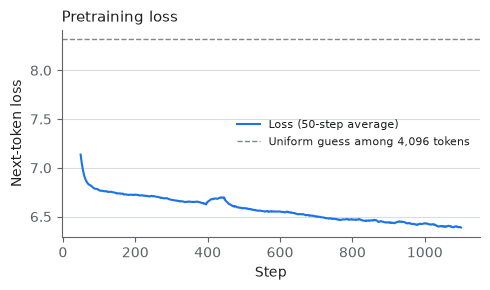

In [13]:
#@title Pretrain from scratch for a few minutes - run this cell { display-mode: "form" }
import pandas as pd
from transformers import AutoConfig, AutoModelForCausalLM

PRETRAIN_MINUTES = 3
GALAXY = "https://raw.githubusercontent.com/raphaelmourad/Mistral-DNA/e8fc28660dee60b580c1f1b1f33934153804ae56/data"
for name, sub in (("pretrain_config.json", "models/Mixtral-8x7B-v0.1/config.json"),
                  ("hg38_200b_verysmall.csv.gz", "genome_sequences/hg38/sequences_hg38_200b_verysmall.csv.gz")):
    if not (DATA_DIR / name).exists():
        urllib.request.urlretrieve(f"{GALAXY}/{sub}", DATA_DIR / name)

cfg = AutoConfig.from_pretrained(DATA_DIR / "pretrain_config.json")
torch.manual_seed(SEED)
scratch = AutoModelForCausalLM.from_config(cfg, attn_implementation="sdpa").to(DEVICE)
print(f"fresh model: {sum(p.numel() for p in scratch.parameters()) / 1e6:.0f}M parameters, random weights")

genome = pd.read_csv(DATA_DIR / "hg38_200b_verysmall.csv.gz")["text"].astype(str).tolist()
tok.padding_side = "left"
enc = tok(genome, padding="longest", truncation=True, max_length=128, return_tensors="pt")
tok.padding_side = "right"
ids_all, att_all = enc["input_ids"], enc["attention_mask"]
print(f"{len(genome):,} pieces of genome, tokenized")

auc_before, _ = probe_auc(embed(tok, scratch, S_train), y_train, embed(tok, scratch, S_test), y_test)
print(f"AGO2 probe BEFORE pretraining: {auc_before:.3f}\n")

use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda" and not use_bf16)
opt = torch.optim.AdamW(scratch.parameters(), lr=5e-4, weight_decay=0.01)
losses, step, t0 = [], 0, time.time()
scratch.train()
while time.time() - t0 < PRETRAIN_MINUTES * 60:
    for i in torch.randperm(len(ids_all)).split(32):
        x, a = ids_all[i].to(DEVICE), att_all[i].to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=amp_dtype, enabled=DEVICE.type == "cuda"):
            loss = scratch(input_ids=x, attention_mask=a, labels=x.masked_fill(a == 0, -100)).loss
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        losses.append(loss.item())
        step += 1
        if step % 100 == 0:
            print(f"step {step:5d} | {(time.time() - t0) / 60:4.1f} min | loss {np.mean(losses[-100:]):.3f}")
        if time.time() - t0 > PRETRAIN_MINUTES * 60:
            break

auc_after, _ = probe_auc(embed(tok, scratch, S_train), y_train, embed(tok, scratch, S_test), y_test)
results[f"our model, random weights"] = auc_before
results[f"our model, after {PRETRAIN_MINUTES} min of pretraining"] = auc_after
print(f"\nAGO2 probe AFTER {step} steps ({PRETRAIN_MINUTES} min): {auc_after:.3f}   (before: {auc_before:.3f})")
plt.figure(figsize=(5, 3)); plt.plot(pd.Series(losses).rolling(50).mean(), c=ACCENT, label="Loss (50-step average)")
plt.axhline(np.log(len(tok)), ls="--", c=MIDGREY, lw=1, label=f"Uniform guess among {len(tok):,} tokens")
plt.xlabel("Step"); plt.ylabel("Next-token loss"); plt.title("Pretraining loss"); plt.legend()
plt.grid(axis="y"); plt.tight_layout(); plt.show()
del scratch
torch.cuda.empty_cache()

In [14]:
#@title Summary - run this cell { display-mode: "form" }
import json
for k, v in sorted(results.items(), key=lambda kv: kv[1]):
    print(f"{v:.3f}  {'█' * int((v - 0.5) * 80):40s} {k}")
_ = (DATA_DIR / "my_slot5_results.json").write_text(json.dumps(results, indent=1))

0.554  ████                                     our model, random weights
0.722  █████████████████                        our model, after 3 min of pretraining
0.782  ██████████████████████                   Mistral-DNA (16M), pretrained
0.788  ███████████████████████                  Nucleotide Transformer (486M), pretrained


### Before Slot 6

**Reading the loss.** The loss measures how surprised the model is by the true next token. A
uniform guess among 4,096 tokens gives ln 4096 ≈ 8.3 (the dashed line). A loss below that line
means the model has picked up some regularity in the genome.

* On the embeddings of the random-weight model, the probe is close to a coin flip. Three minutes of pretraining already
  raises it. Compare your before and after numbers.
* A 30× larger model scores about the same here: 0.78 vs 0.79 is within the ±0.025 noise of a
  1,000-sequence test set.
* With the language model frozen, both probes score below the small CNN from Slot 2 (~0.86).

An AUROC does not tell you what signal a model uses. Slot 6 tests that.

In [15]:
#@title Download your vectors (optional: Slot 6 can use them, or ours) - run this cell { display-mode: "form" }
download_outputs("my_emb_mistral17m.npz")

my_emb_mistral17m.npz: saved at /data/home/hoory/ai-days-2026/run_student/data/my_emb_mistral17m.npz
